# IPL Match & Player Performance Analysis
PBL Micro Project â€” Python for Data Science (BE05000231)

Pipeline: load â†’ inspect â†’ clean â†’ descriptive stats â†’ EDA â†’ segmentation â†’ visualisation â†’ insights

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('Set2')
print('pandas', pd.__version__, '| numpy', np.__version__)

pandas 3.0.5 | numpy 2.5.2


## 1. Load and Inspect both files

In [2]:
# Jupyter sets the working directory to the notebook's own folder, so these
# paths resolve relative to this file - the repo runs wherever it is cloned.
BASE = os.getcwd()
OUT = os.path.join(os.path.dirname(BASE), 'Required output')
os.makedirs(OUT, exist_ok=True)
matches = pd.read_csv(os.path.join(BASE, 'matches.csv'))
deliveries = pd.read_csv(os.path.join(BASE, 'deliveries.csv'))

print('matches:', matches.shape)
print('deliveries:', deliveries.shape)
matches.head()

matches: (1095, 20)
deliveries: (260920, 17)


,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
0,335982,2007/08,Bangalore,2008-04-18,League,BB McCullum,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,223.0,20.0,N,NaN,Asad Rauf,RE Koertzen
1,335983,2007/08,Chandigarh,2008-04-19,League,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,runs,33.0,241.0,20.0,N,NaN,MR Benson,SL Shastri
2,335984,2007/08,Delhi,2008-04-19,League,MF Maharoof,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,Delhi Daredevils,wickets,9.0,130.0,20.0,N,NaN,Aleem Dar,GA Pratapkumar
3,335985,2007/08,Mumbai,2008-04-20,League,MV Boucher,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Royal Challengers Bangalore,wickets,5.0,166.0,20.0,N,NaN,SJ Davis,DJ Harper
4,335986,2007/08,Kolkata,2008-04-20,League,DJ Hussey,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,Kolkata Knight Riders,wickets,5.0,111.0,20.0,N,NaN,BF Bowden,K Hariharan


In [3]:
matches.dtypes

id                   int64
season                 str
city                   str
date                   str
match_type             str
player_of_match        str
venue                  str
team1                  str
team2                  str
toss_winner            str
toss_decision          str
winner                 str
result                 str
result_margin      float64
target_runs        float64
target_overs       float64
super_over             str
method                 str
umpire1                str
umpire2                str
dtype: object

In [4]:
print('--- matches missing values ---'); print(matches.isnull().sum())
print('--- deliveries missing values ---'); print(deliveries.isnull().sum())
print('matches duplicates:', matches.duplicated().sum())
print('deliveries duplicates:', deliveries.duplicated().sum())

--- matches missing values ---
id                    0
season                0
city                 51
date                  0
match_type            0
player_of_match       5
venue                 0
team1                 0
team2                 0
toss_winner           0
toss_decision         0
winner                5
result                0
result_margin        19
target_runs           3
target_overs          3
super_over            0
method             1074
umpire1               0
umpire2               0
dtype: int64
--- deliveries missing values ---
match_id                 0
inning                   0
batting_team             0
bowling_team             0
over                     0
ball                     0
batter                   0
bowler                   0
non_striker              0
batsman_runs             0
extra_runs               0
total_runs               0
extras_type         246795
is_wicket                0
player_dismissed    247970
dismissal_kind      247970
fielder   

## 2. Data Cleaning

In [5]:
# 2.1 strip whitespace in object columns
for col in matches.select_dtypes('object'):
    matches[col] = matches[col].astype(str).str.strip().replace('nan', np.nan)
for col in deliveries.select_dtypes('object'):
    deliveries[col] = deliveries[col].astype(str).str.strip().replace('nan', np.nan)

# 2.2 date parsing
matches['date'] = pd.to_datetime(matches['date'], errors='coerce')

# 2.3 fill missing categorical values
matches['city'] = matches['city'].fillna(matches['city'].mode()[0])
matches['player_of_match'] = matches['player_of_match'].fillna('Unknown')
matches['winner'] = matches['winner'].fillna('No Result')
matches['method'] = matches['method'].fillna('Normal')

# 2.4 numeric columns: fill missing margins with median
for col in ['result_margin', 'target_runs', 'target_overs']:
    matches[col] = matches[col].fillna(matches[col].median())

# 2.5 deliveries: fill dismissal fields (no wicket -> 'Not Out' handled later)
deliveries['dismissal_kind'] = deliveries['dismissal_kind'].fillna('Not Applicable')
deliveries['fielder'] = deliveries['fielder'].fillna('None')
deliveries['extras_type'] = deliveries['extras_type'].fillna('None')

# 2.6 merge renamed franchises into one canonical name per team
# (the dataset stores pre- and post-rename names as separate teams)
TEAM_RENAMES = {
    'Royal Challengers Bangalore': 'Royal Challengers Bengaluru',
    'Delhi Daredevils': 'Delhi Capitals',
    'Kings XI Punjab': 'Punjab Kings',
    'Rising Pune Supergiants': 'Rising Pune Supergiant',
}
for col in ['team1', 'team2', 'toss_winner', 'winner']:
    matches[col] = matches[col].replace(TEAM_RENAMES)
for col in ['batting_team', 'bowling_team']:
    deliveries[col] = deliveries[col].replace(TEAM_RENAMES)
print('Distinct franchises after merge:', len(set(matches['team1']) | set(matches['team2'])))

print('Cleaned matches nulls:', matches.isnull().sum().sum())
print('Cleaned deliveries nulls:', deliveries.isnull().sum().sum())
matches[['city','winner','method','result_margin']].head()

C:\Users\husai\AppData\Local\Temp\ipykernel_11440\1531456529.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in matches.select_dtypes('object'):
C:\Users\husai\AppData\Local\Temp\ipykernel_11440\1531456529.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3

Distinct franchises after merge: 15
Cleaned matches nulls: 0
Cleaned deliveries nulls: 247970


,city,winner,method,result_margin
0,Bangalore,Kolkata Knight Riders,Normal,140.0
1,Chandigarh,Chennai Super Kings,Normal,33.0
2,Delhi,Delhi Capitals,Normal,9.0
3,Mumbai,Royal Challengers Bengaluru,Normal,5.0
4,Kolkata,Kolkata Knight Riders,Normal,5.0


## 3. Merge for analysis

In [6]:
df = deliveries.merge(matches[['id','season','city','date','venue','winner','toss_winner','toss_decision','team1','team2']],
                      left_on='match_id', right_on='id', how='left')
df.drop(columns=['id']).head()

,match_id,inning,batting_team,bowling_team,over,ball,batter,bowler,non_striker,batsman_runs,...,fielder,season,city,date,venue,winner,toss_winner,toss_decision,team1,team2
0,335982,1,Kolkata Knight Riders,Royal Challengers Bengaluru,0,1,SC Ganguly,P Kumar,BB McCullum,0,...,None,2007/08,Bangalore,2008-04-18,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bengaluru,field,Royal Challengers Bengaluru,Kolkata Knight Riders
1,335982,1,Kolkata Knight Riders,Royal Challengers Bengaluru,0,2,BB McCullum,P Kumar,SC Ganguly,0,...,None,2007/08,Bangalore,2008-04-18,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bengaluru,field,Royal Challengers Bengaluru,Kolkata Knight Riders
2,335982,1,Kolkata Knight Riders,Royal Challengers Bengaluru,0,3,BB McCullum,P Kumar,SC Ganguly,0,...,None,2007/08,Bangalore,2008-04-18,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bengaluru,field,Royal Challengers Bengaluru,Kolkata Knight Riders
3,335982,1,Kolkata Knight Riders,Royal Challengers Bengaluru,0,4,BB McCullum,P Kumar,SC Ganguly,0,...,None,2007/08,Bangalore,2008-04-18,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bengaluru,field,Royal Challengers Bengaluru,Kolkata Knight Riders
4,335982,1,Kolkata Knight Riders,Royal Challengers Bengaluru,0,5,BB McCullum,P Kumar,SC Ganguly,0,...,None,2007/08,Bangalore,2008-04-18,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bengaluru,field,Royal Challengers Bengaluru,Kolkata Knight Riders


In [7]:
# Innings totals per team per match (like order totals)
innings = df.groupby(['match_id','season','city','venue','batting_team','inning'], as_index=False)['total_runs'].sum()
innings = innings.rename(columns={'total_runs':'innings_runs'})
innings.head()

,match_id,season,city,venue,batting_team,inning,innings_runs
0,335982,2007/08,Bangalore,M Chinnaswamy Stadium,Kolkata Knight Riders,1,222
1,335982,2007/08,Bangalore,M Chinnaswamy Stadium,Royal Challengers Bengaluru,2,82
2,335983,2007/08,Chandigarh,"Punjab Cricket Association Stadium, Mohali",Chennai Super Kings,1,240
3,335983,2007/08,Chandigarh,"Punjab Cricket Association Stadium, Mohali",Punjab Kings,2,207
4,335984,2007/08,Delhi,Feroz Shah Kotla,Delhi Capitals,2,132


## 4. Descriptive Statistics

In [8]:
innings['innings_runs'].describe()

count    2217.000000
mean      156.858818
std        36.674911
min         2.000000
25%       138.000000
50%       160.000000
75%       179.000000
max       287.000000
Name: innings_runs, dtype: float64

In [9]:
deliveries[['batsman_runs','extra_runs','total_runs','is_wicket']].describe()

,batsman_runs,extra_runs,total_runs,is_wicket
count,260920.000000,260920.000000,260920.000000,260920.000000
mean,1.265001,0.067806,1.332807,0.049632
std,1.639298,0.343265,1.626416,0.217184
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000
50%,1.000000,0.000000,1.000000,0.000000
75%,1.000000,0.000000,1.000000,0.000000
max,6.000000,7.000000,7.000000,1.000000


## 5. Derived column + Segmentation (like customer segments)

In [10]:
# A high-value innings: total >= 180
innings['IsHighScoreInnings'] = (innings['innings_runs'] >= 180).astype(int)

# Team seasons by strength: Low / Medium / High Value teams by total runs across seasons
team_runs = innings.groupby('batting_team')['innings_runs'].sum().sort_values()
q1, q2 = team_runs.quantile([1/3, 2/3])
def segment(x):
    if x <= q1: return 'Low Value'
    if x <= q2: return 'Medium Value'
    return 'High Value'
team_segment = team_runs.apply(segment)
print('Segment cutoffs: Q1 =', round(q1,1), ' Q2 =', round(q2,1))
team_segment

Segment cutoffs: Q1 = 7674.7  Q2 = 38818.0


batting_team
Kochi Tuskers Kerala              Low Value
Rising Pune Supergiant            Low Value
Gujarat Lions                     Low Value
Pune Warriors                     Low Value
Lucknow Super Giants              Low Value
Gujarat Titans                 Medium Value
Deccan Chargers                Medium Value
Sunrisers Hyderabad            Medium Value
Rajasthan Royals               Medium Value
Chennai Super Kings            Medium Value
Delhi Capitals                   High Value
Kolkata Knight Riders            High Value
Punjab Kings                     High Value
Royal Challengers Bengaluru      High Value
Mumbai Indians                   High Value
Name: innings_runs, dtype: str

## 6. Visualisations (9 charts + 2x2 dashboard)

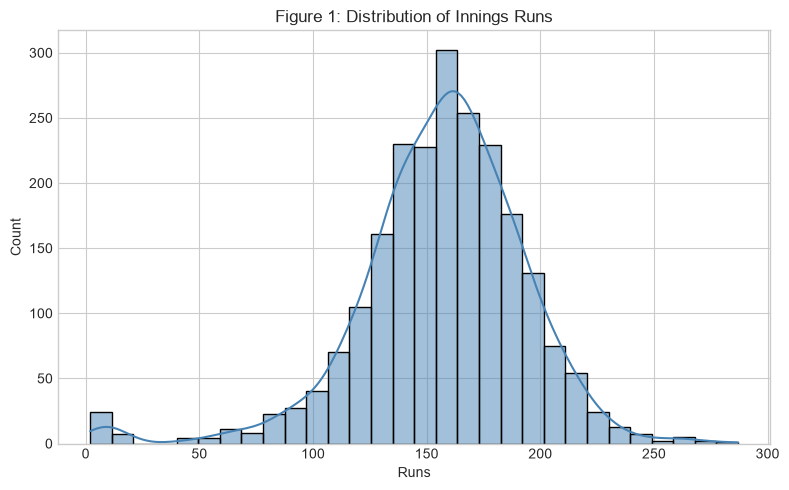

In [11]:
# Fig 1: Distribution of innings runs
plt.figure(figsize=(8,5))
sns.histplot(innings['innings_runs'], bins=30, kde=True, color='steelblue')
plt.title('Figure 1: Distribution of Innings Runs'); plt.xlabel('Runs'); plt.tight_layout(); plt.savefig(os.path.join(OUT, 'fig1_runs_distribution.png'), dpi=120); plt.show()

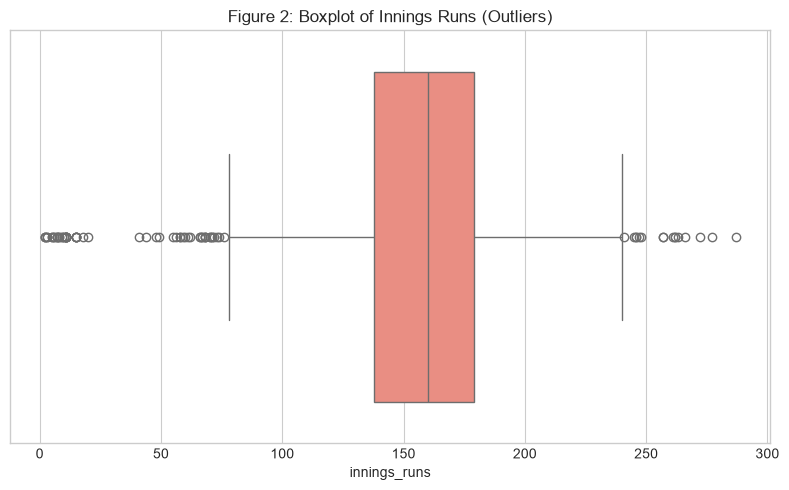

In [12]:
# Fig 2: Boxplot & outliers of innings runs
plt.figure(figsize=(8,5))
sns.boxplot(x=innings['innings_runs'], color='salmon')
plt.title('Figure 2: Boxplot of Innings Runs (Outliers)'); plt.tight_layout(); plt.savefig(os.path.join(OUT, 'fig2_runs_boxplot.png'), dpi=120); plt.show()

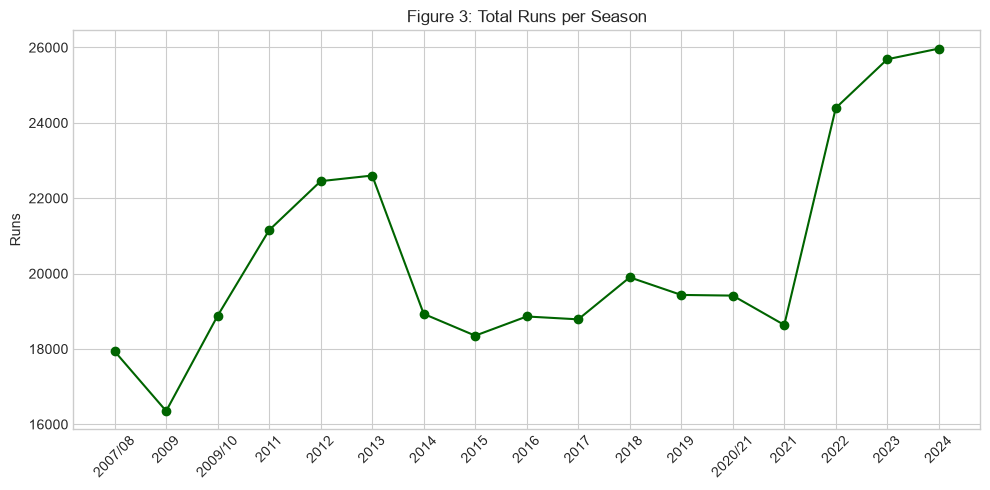

In [13]:
# Fig 3: Total runs scored per season (line)
season_runs = innings.groupby('season')['innings_runs'].sum()
plt.figure(figsize=(10,5))
plt.plot(season_runs.index, season_runs.values, marker='o', color='darkgreen')
plt.title('Figure 3: Total Runs per Season'); plt.xticks(rotation=45); plt.ylabel('Runs'); plt.tight_layout(); plt.savefig(os.path.join(OUT, 'fig3_runs_per_season.png'), dpi=120); plt.show()

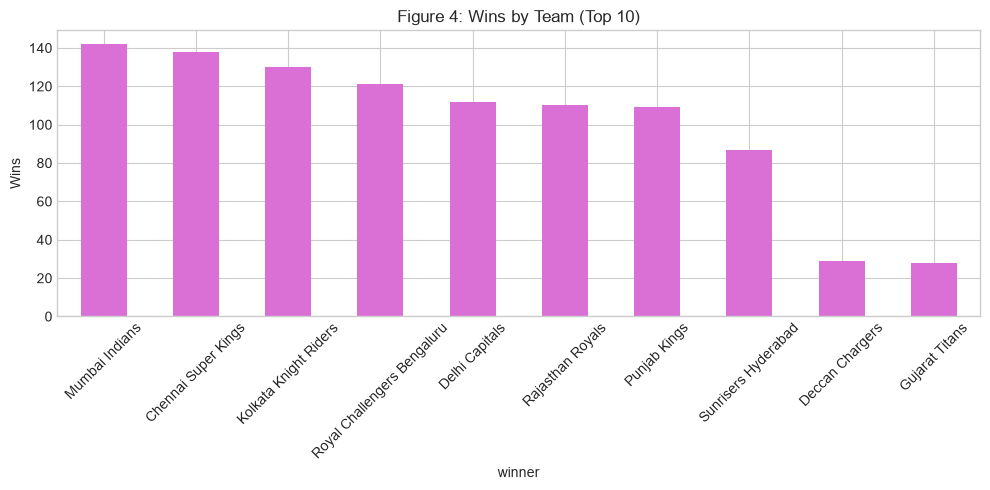

In [14]:
# Fig 4: Top 10 teams by wins
wins = matches[matches['result'].isin(['runs','wickets'])]['winner'].value_counts().head(10)
plt.figure(figsize=(10,5))
wins.plot(kind='bar', color='orchid')
plt.title('Figure 4: Wins by Team (Top 10)'); plt.ylabel('Wins'); plt.xticks(rotation=45); plt.tight_layout(); plt.savefig(os.path.join(OUT, 'fig4_team_wins.png'), dpi=120); plt.show()

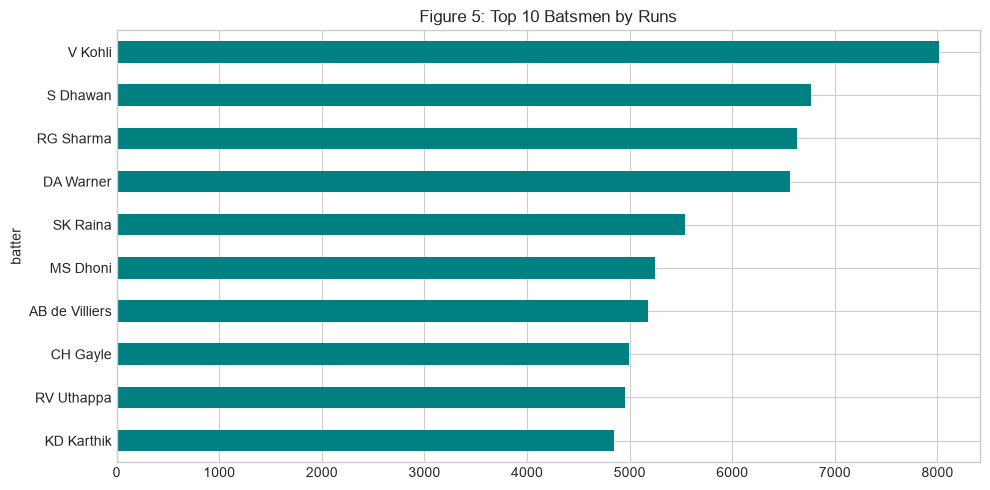

In [15]:
# Fig 5: Top 10 batsmen
bat = deliveries.groupby('batter')['batsman_runs'].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(10,5))
bat.plot(kind='barh', color='teal'); plt.gca().invert_yaxis()
plt.title('Figure 5: Top 10 Batsmen by Runs'); plt.tight_layout(); plt.savefig(os.path.join(OUT, 'fig5_top_batsmen.png'), dpi=120); plt.show()

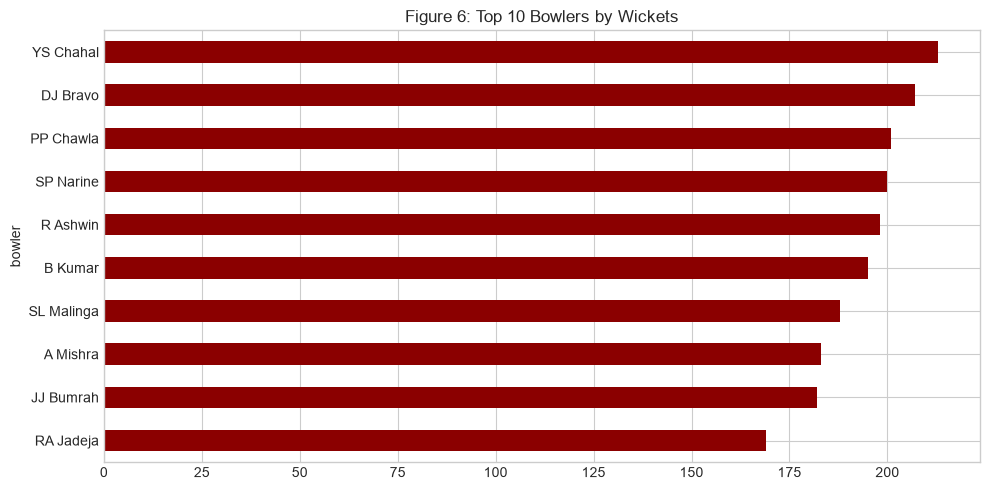

In [16]:
# Fig 6: Top 10 bowlers by wickets
bowl = deliveries[deliveries['is_wicket']==1].groupby('bowler').size().sort_values(ascending=False).head(10)
plt.figure(figsize=(10,5))
bowl.plot(kind='barh', color='darkred'); plt.gca().invert_yaxis()
plt.title('Figure 6: Top 10 Bowlers by Wickets'); plt.tight_layout(); plt.savefig(os.path.join(OUT, 'fig6_top_bowlers.png'), dpi=120); plt.show()

toss_win_match_win
True     50.8
False    49.2
Name: proportion, dtype: float64


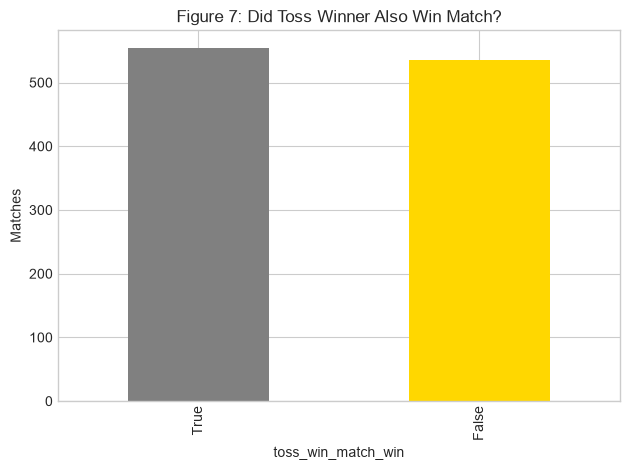

In [17]:
# Fig 7: Toss decision and win impact
tossed = matches[matches['winner'] != 'No Result'].copy()
tossed['toss_win_match_win'] = tossed['toss_winner'] == tossed['winner']
print(tossed['toss_win_match_win'].value_counts(normalize=True).round(3) * 100)
tossed['toss_win_match_win'].value_counts().plot(kind='bar', color=['grey','gold'])
plt.title('Figure 7: Did Toss Winner Also Win Match?'); plt.ylabel('Matches'); plt.tight_layout(); plt.savefig(os.path.join(OUT, 'fig7_toss_impact.png'), dpi=120); plt.show()

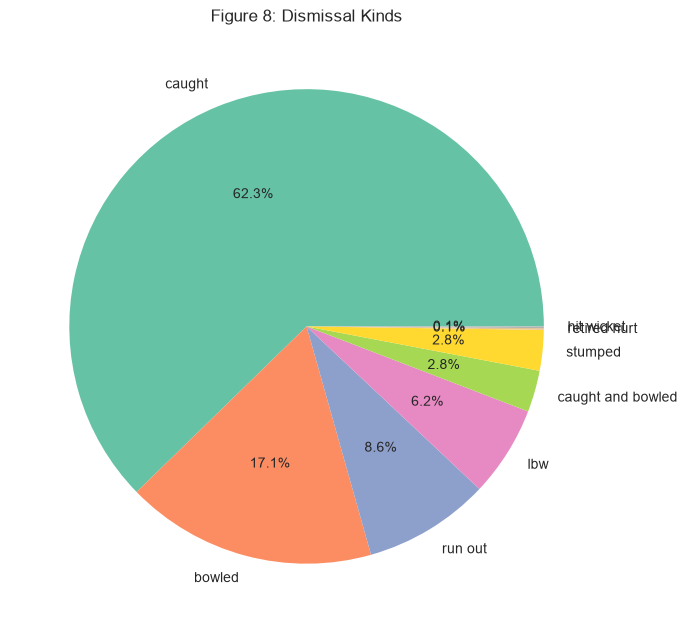

In [18]:
# Fig 8: Dismissal kinds
dk = deliveries[deliveries['is_wicket']==1]['dismissal_kind'].value_counts().head(8)
plt.figure(figsize=(7,7)); dk.plot(kind='pie', autopct='%1.1f%%'); plt.ylabel('')
plt.title('Figure 8: Dismissal Kinds'); plt.tight_layout(); plt.savefig(os.path.join(OUT, 'fig8_dismissals.png'), dpi=120); plt.show()

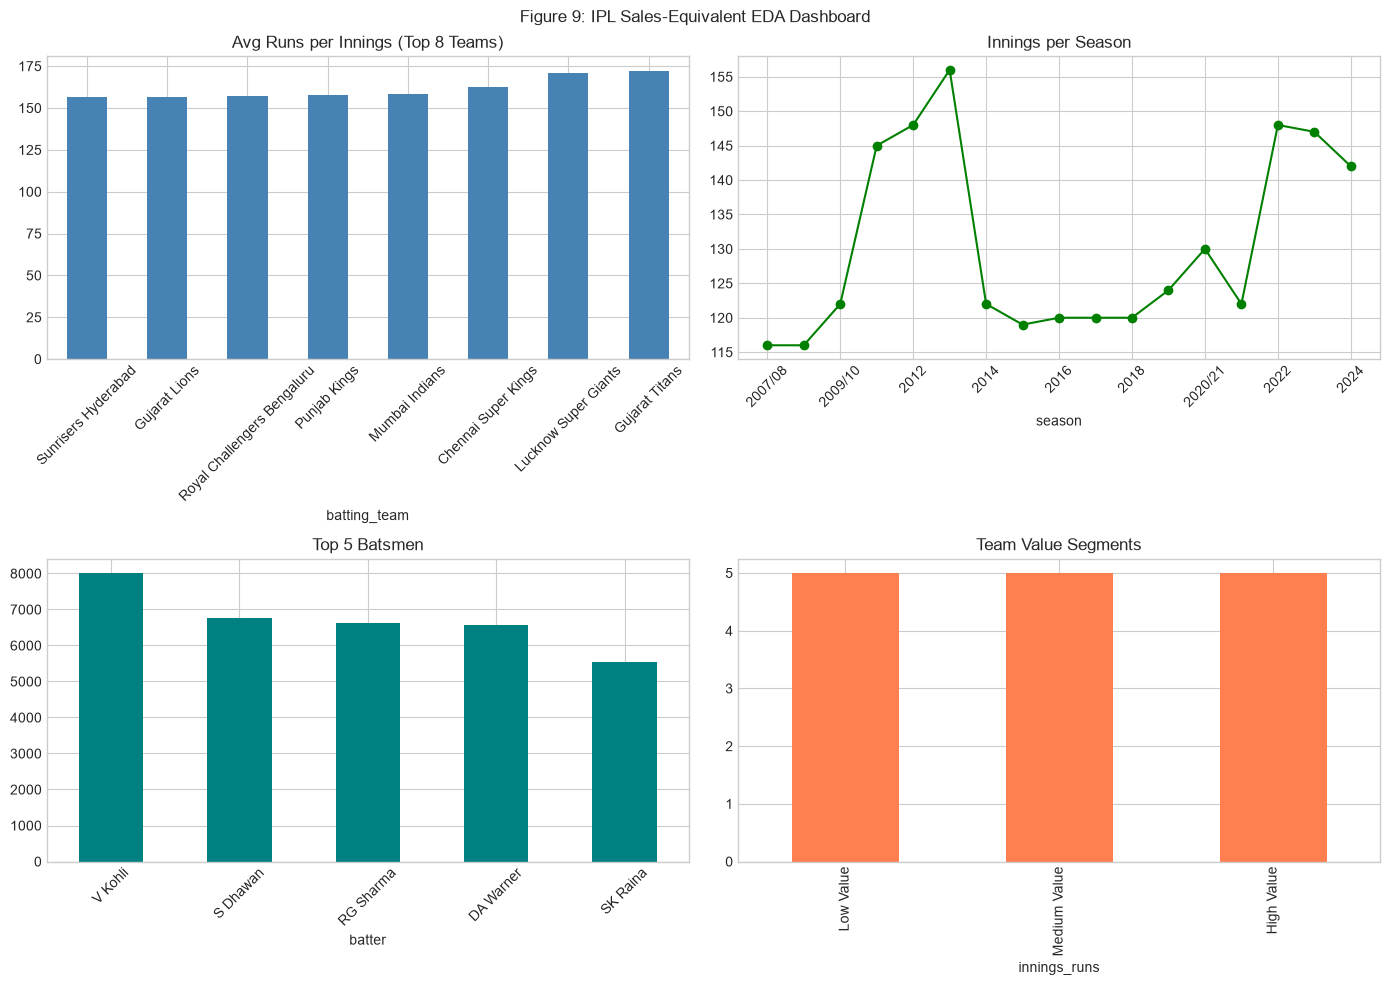

In [19]:
# Fig 9: 2x2 dashboard
fig, axes = plt.subplots(2, 2, figsize=(14,10))
innings.groupby('batting_team')['innings_runs'].mean().sort_values().tail(8).plot(kind='bar', ax=axes[0,0], color='steelblue')
axes[0,0].set_title('Avg Runs per Innings (Top 8 Teams)'); axes[0,0].tick_params(axis='x', rotation=45)
innings.groupby('season')['inning'].count().plot(ax=axes[0,1], marker='o', color='green')
axes[0,1].set_title('Innings per Season'); axes[0,1].tick_params(axis='x', rotation=45)
bat.head(5).plot(kind='bar', ax=axes[1,0], color='teal'); axes[1,0].set_title('Top 5 Batsmen'); axes[1,0].tick_params(axis='x', rotation=45)
team_segment.value_counts().plot(kind='bar', ax=axes[1,1], color='coral'); axes[1,1].set_title('Team Value Segments')
plt.suptitle('Figure 9: IPL Sales-Equivalent EDA Dashboard'); plt.tight_layout(); plt.savefig(os.path.join(OUT, 'fig9_dashboard.png'), dpi=120); plt.show()

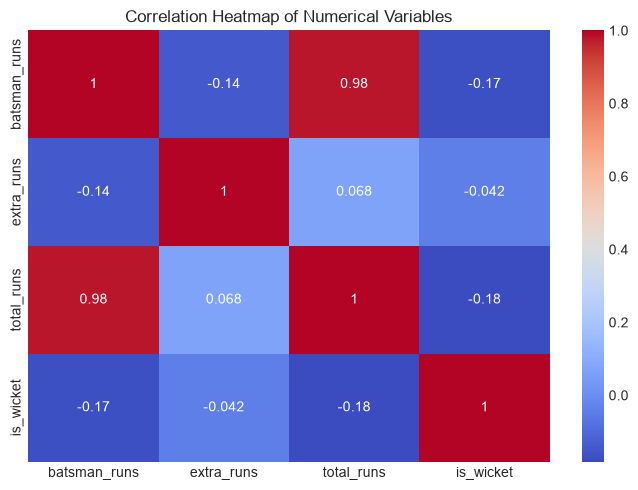

In [20]:
# Correlation heatmap
num = deliveries[['batsman_runs','extra_runs','total_runs','is_wicket']]
plt.figure(figsize=(7,5)); sns.heatmap(num.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap of Numerical Variables'); plt.tight_layout(); plt.savefig(os.path.join(OUT, 'fig10_correlation.png'), dpi=120); plt.show()

## 7. Key findings (for report)

In [21]:
print('Total matches:', matches['id'].nunique())
print('Total innings:', len(innings))
print('Total runs in dataset:', innings['innings_runs'].sum())
print('Highest scoring innings:', innings['innings_runs'].max(), 'runs')
print('High score innings (>=180):', int(innings['IsHighScoreInnings'].sum()))
print('Top team by wins:', wins.index[0], wins.iloc[0], 'wins')
print('Most runs player:', bat.index[0], bat.iloc[0])
print('Most wickets player:', bowl.index[0], bowl.iloc[0])
print('Toss winner won match %:', round(tossed['toss_win_match_win'].mean()*100,1))

Total matches: 1095
Total innings: 2217
Total runs in dataset: 347756
Highest scoring innings: 287 runs
High score innings (>=180): 551
Top team by wins: Mumbai Indians 142 wins
Most runs player: V Kohli 8014
Most wickets player: YS Chahal 213
Toss winner won match %: 50.8
